# Digital Image Processing Lab – Lab Task 05
## Spatial Filtering and Convolution

**Name:** YOUR NAME  
**Roll No:** 2024-SE-16  
**Session:** 2024-28 (SE) | **Semester:** Fifth  
**Lab Instructor:** Engr. Fahad Nisar  
**Department of Software Engineering, The University of Azad Jammu and Kashmir**

**Objective:** implement 2D convolution from first principles, then use mean, Gaussian and median filters to remove noise from real images, checking the hand calculations and comparing against OpenCV.

**Filtering rules followed throughout (R1–R6):** same-size output with reflect padding (R1) · float64 maths, `round` + `clip` to `uint8` only at the end (R2) · smoothing kernels sum to 1 (R3) · odd kernel sizes 3/5/7 (R4) · noise with `seed=5` (R5) · every result judged against the clean original (R6).

---
## Task 1 – Load the three test images
`camera`, `coins` and `chelsea` come from `skimage.data`. `chelsea` is a colour photo, so it is converted to grayscale. The arrays are made **read-only** and fingerprinted with an MD5 hash, so the final cell can prove the originals were never modified.

NumPy 2.5.4 | OpenCV 5.0.0
camera   shape=(512, 512)  dtype=uint8  min=  0  max=255
coins    shape=(303, 384)  dtype=uint8  min=  1  max=252
chelsea  shape=(300, 451)  dtype=uint8  min=  4  max=194


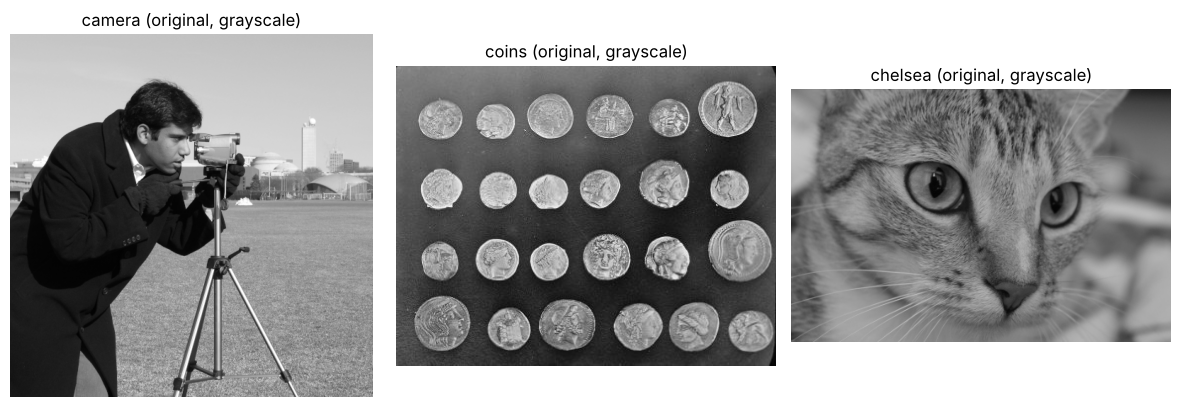

In [1]:
import hashlib, time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data
from skimage.metrics import peak_signal_noise_ratio as psnr

plt.rcParams["figure.dpi"] = 100

camera  = data.camera()
coins   = data.coins()
chelsea = cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY)   # colour -> grayscale

originals = {"camera": camera, "coins": coins, "chelsea": chelsea}
for img in originals.values():
    img.setflags(write=False)            # keep the originals unchanged
fingerprints = {k: hashlib.md5(v.tobytes()).hexdigest() for k, v in originals.items()}

print("NumPy", np.__version__, "| OpenCV", cv2.__version__)
for k, v in originals.items():
    print(f"{k:8s} shape={v.shape}  dtype={v.dtype}  min={v.min():3d}  max={v.max():3d}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (k, v) in zip(axes, originals.items()):
    ax.imshow(v, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{k} (original, grayscale)")
    ax.axis("off")
plt.tight_layout()
plt.show()

---
## Task 2 – `conv2d_loop(img, kernel)` from first principles
Steps (R1, R2):
1. Convert image and kernel to `float64`.
2. **Flip** the kernel in both directions – that is what makes it true *convolution* rather than correlation.
3. **Reflect-pad** the image by `k//2` on every side so border pixels also have a full neighbourhood.
4. For every pixel, multiply the neighbourhood by the flipped kernel and add it up.
5. Return a `float64` array the **same size** as the input (rounding/clipping to `uint8` happens later).

In [2]:
def conv2d_loop(img, kernel):
    img    = np.asarray(img,    dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("kernel dimensions must be odd")
    ph, pw = kh // 2, kw // 2
    flipped = kernel[::-1, ::-1]                              # true convolution
    padded  = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect")
    H, W    = img.shape
    out     = np.zeros((H, W), dtype=np.float64)
    for y in range(H):
        for x in range(W):
            window   = padded[y:y + kh, x:x + kw]             # neighbourhood of (y, x)
            out[y, x] = np.sum(window * flipped)              # weighted sum
    return out

# quick sanity check on a tiny array: an impulse should reproduce the kernel itself
impulse = np.zeros((5, 5)); impulse[2, 2] = 1
k_test  = np.arange(1, 10).reshape(3, 3)
print("kernel:\n", k_test)
print("conv2d_loop(impulse, kernel) centre 3x3:\n", conv2d_loop(impulse, k_test)[1:4, 1:4])
print("output dtype:", conv2d_loop(impulse, k_test).dtype, "| shape:", conv2d_loop(impulse, k_test).shape)

kernel:
 [[1 2 3]
 [4 5 6]
 [7 8 9]]
conv2d_loop(impulse, kernel) centre 3x3:
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
output dtype: float64 | shape: (5, 5)


---
## Task 3 – Verify `conv2d_loop` against OpenCV
`cv2.filter2D` actually computes *correlation*, so to get true convolution it must be given the **flipped** kernel. I compare on the real `camera` image (512×512) in `float64` (no rounding) with `BORDER_REFLECT_101`, which is exactly what NumPy's `mode="reflect"` does. Three kernels are tested; the last one is deliberately **asymmetric** so that a missing flip would show up as a large error.

In [3]:
kernels = {
    "mean 3x3":            np.full((3, 3), 1 / 9),
    "gaussian 3x3":        np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16,
    "asymmetric (test)":   np.array([[1, 2, 3], [0, 0, 0], [-1, -2, -3]], dtype=np.float64),
}

for name, k in kernels.items():
    t0 = time.time()
    mine = conv2d_loop(camera, k)
    cv   = cv2.filter2D(camera.astype(np.float64), cv2.CV_64F, k[::-1, ::-1],
                        borderType=cv2.BORDER_REFLECT_101)
    wrong = cv2.filter2D(camera.astype(np.float64), cv2.CV_64F, k,          # NOT flipped
                         borderType=cv2.BORDER_REFLECT_101)
    print(f"{name:20s} max |mine - OpenCV| = {np.abs(mine - cv).max():.3e}   "
          f"(if kernel were NOT flipped: {np.abs(mine - wrong).max():.1f})   [{time.time()-t0:.1f}s]")

# same comparison after rounding to uint8 (what the rest of the lab uses)
mine_u8 = np.clip(np.rint(conv2d_loop(camera, kernels["mean 3x3"])), 0, 255).astype(np.uint8)
cv_u8   = cv2.blur(camera, (3, 3))
print("\nmean 3x3 as uint8 images:  largest difference =", np.abs(mine_u8.astype(int) - cv_u8.astype(int)).max(),
      "grey level(s);  pixels that differ =", int((mine_u8 != cv_u8).sum()))

mean 3x3             max |mine - OpenCV| = 5.684e-14   (if kernel were NOT flipped: 0.0)   [0.8s]


gaussian 3x3         max |mine - OpenCV| = 0.000e+00   (if kernel were NOT flipped: 0.0)   [0.8s]


asymmetric (test)    max |mine - OpenCV| = 0.000e+00   (if kernel were NOT flipped: 2316.0)   [0.7s]



mean 3x3 as uint8 images:  largest difference = 0 grey level(s);  pixels that differ = 0


---
## Task 4 – Noise functions (R5) and the smoothing kernels (R3, R4)

* `add_gaussian_noise(img, sigma=20, seed=5)` – adds zero-mean Gaussian noise (σ = 20) to every pixel, then rounds and clips to 0–255.
* `add_salt_pepper(img, amount=0.05, seed=5)` – turns 5 % of the pixels into impulses: half become 255 (salt), half become 0 (pepper).

Both use a local `np.random.default_rng(seed)` so every run produces the same noisy images.

In [4]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng   = np.random.default_rng(seed)
    noisy = img.astype(np.float64) + rng.normal(0.0, sigma, img.shape)
    return np.clip(np.rint(noisy), 0, 255).astype(np.uint8)

def add_salt_pepper(img, amount=0.05, seed=5):
    rng   = np.random.default_rng(seed)
    r     = rng.random(img.shape)
    noisy = img.copy()
    noisy[r < amount / 2]       = 0        # pepper  (2.5 % of pixels)
    noisy[r > 1 - amount / 2]   = 255      # salt    (2.5 % of pixels)
    return noisy

noisy = {}
for name, img in originals.items():
    noisy[(name, "gaussian")] = add_gaussian_noise(img, sigma=20, seed=5)
    noisy[(name, "salt&pepper")] = add_salt_pepper(img, amount=0.05, seed=5)

for (name, kind), n in noisy.items():
    changed = (n != originals[name]).mean() * 100
    print(f"{name:8s} {kind:12s} PSNR vs clean = {psnr(originals[name], n):5.2f} dB   pixels changed = {changed:5.1f} %")

camera   gaussian     PSNR vs clean = 22.40 dB   pixels changed =  97.9 %
camera   salt&pepper  PSNR vs clean = 17.69 dB   pixels changed =   5.0 %
coins    gaussian     PSNR vs clean = 22.20 dB   pixels changed =  97.9 %
coins    salt&pepper  PSNR vs clean = 18.11 dB   pixels changed =   5.0 %
chelsea  gaussian     PSNR vs clean = 22.12 dB   pixels changed =  97.9 %
chelsea  salt&pepper  PSNR vs clean = 18.73 dB   pixels changed =   5.0 %


In [5]:
def check_odd(k):
    if k % 2 == 0 or k not in (3, 5, 7):
        raise ValueError(f"kernel size must be 3, 5 or 7 (odd), got {k}")

def mean_kernel(k):
    check_odd(k)
    return np.full((k, k), 1.0 / (k * k))

def gaussian_kernel(k):
    check_odd(k)
    g = cv2.getGaussianKernel(k, 0).ravel()          # same 1-D weights cv2.GaussianBlur uses
    return np.outer(g, g)

# R3: weights of every smoothing kernel must sum to 1
for k in (3, 5, 7):
    for label, ker in (("mean", mean_kernel(k)), ("gaussian", gaussian_kernel(k))):
        s = ker.sum()
        print(f"{label:8s} {k}x{k}  weight sum = {s:.12f}   sums to 1: {np.isclose(s, 1.0)}")

print("\nGaussian 3x3 kernel x16 (the 1-2-1 kernel):\n", np.rint(gaussian_kernel(3) * 16).astype(int))
print("Gaussian 5x5 kernel x256:\n", np.rint(gaussian_kernel(5) * 256).astype(int))

mean     3x3  weight sum = 1.000000000000   sums to 1: True
gaussian 3x3  weight sum = 1.000000000000   sums to 1: True
mean     5x5  weight sum = 1.000000000000   sums to 1: True
gaussian 5x5  weight sum = 1.000000000000   sums to 1: True
mean     7x7  weight sum = 1.000000000000   sums to 1: True
gaussian 7x7  weight sum = 1.000000000000   sums to 1: True

Gaussian 3x3 kernel x16 (the 1-2-1 kernel):
 [[1 2 1]
 [2 4 2]
 [1 2 1]]
Gaussian 5x5 kernel x256:
 [[ 1  4  6  4  1]
 [ 4 16 24 16  4]
 [ 6 24 36 24  6]
 [ 4 16 24 16  4]
 [ 1  4  6  4  1]]


---
## Task 5 – Mean, Gaussian and median filters (3×3, 5×5, 7×7)
* **Mean** – all weights `1/size²`. First applied with my own `conv2d_loop` and with `cv2.blur`; the two must agree within rounding.
* **Gaussian** – `cv2.GaussianBlur` with the discrete Gaussian weights.
* **Median** – `cv2.medianBlur`; an even size is rejected.

All three are computed in `float64` (median works on the 8-bit values) and converted to `uint8` only at the end with `round` + `clip` (R2).

In [6]:
def to_uint8(x):
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)         # R2: round, clip, convert last

def mean_filter(img, k):
    check_odd(k)
    return to_uint8(cv2.blur(img.astype(np.float64), (k, k)))

def gaussian_filter(img, k):
    check_odd(k)
    return to_uint8(cv2.GaussianBlur(img.astype(np.float64), (k, k), 0))

def median_filter(img, k):
    check_odd(k)
    return cv2.medianBlur(img, k)

FILTERS = {"mean": mean_filter, "gaussian": gaussian_filter, "median": median_filter}

# --- mean filter: my conv2d_loop vs cv2.blur (on the coins image, every size) ---
for k in (3, 5, 7):
    mine = to_uint8(conv2d_loop(coins, mean_kernel(k)))
    cvb  = mean_filter(coins, k)
    d    = np.abs(mine.astype(int) - cvb.astype(int))
    print(f"mean {k}x{k}: conv2d_loop vs cv2.blur  max difference = {d.max()} grey level, "
          f"differing pixels = {int((d > 0).sum())} of {d.size}")

# --- Gaussian: conv2d_loop with the same kernel vs cv2.GaussianBlur (coins, 5x5) ---
g_mine = to_uint8(conv2d_loop(coins, gaussian_kernel(5)))
g_cv   = gaussian_filter(coins, 5)
print("gaussian 5x5: conv2d_loop vs cv2.GaussianBlur max difference =",
      np.abs(g_mine.astype(int) - g_cv.astype(int)).max())

# --- apply every filter at every size to every noisy image ---
results = {}
for (name, kind), n in noisy.items():
    for fname, f in FILTERS.items():
        for k in (3, 5, 7):
            results[(name, kind, fname, k)] = f(n, k)
print("\nfiltered images produced:", len(results))

mean 3x3: conv2d_loop vs cv2.blur  max difference = 0 grey level, differing pixels = 0 of 116352


mean 5x5: conv2d_loop vs cv2.blur  max difference = 0 grey level, differing pixels = 0 of 116352


mean 7x7: conv2d_loop vs cv2.blur  max difference = 0 grey level, differing pixels = 0 of 116352


gaussian 5x5: conv2d_loop vs cv2.GaussianBlur max difference = 0

filtered images produced: 54


### Compliance checks (R1–R5)

In [7]:
# (1) every filtered output: dtype uint8, values 0-255, same shape as the input  (R1, R2)
bad = 0
for (name, kind, fname, k), out in results.items():
    ok = out.dtype == np.uint8 and out.min() >= 0 and out.max() <= 255 and out.shape == originals[name].shape
    bad += (not ok)
print(f"(1) {len(results)} filtered outputs checked -> uint8, range 0-255, same shape: {bad == 0}")
sample = results[("camera", "gaussian", "mean", 3)]
print("    example:", sample.dtype, sample.shape, "min", sample.min(), "max", sample.max())

# (2) kernel weight sums were printed in Task 4 (all equal 1)  (R3)
print("(2) all mean/gaussian kernel sums equal 1:",
      all(np.isclose(f(k).sum(), 1) for f in (mean_kernel, gaussian_kernel) for k in (3, 5, 7)))

# (3) even kernel size must be rejected  (R4)
try:
    cv2.medianBlur(camera, 4)
except cv2.error as e:
    print("(3) cv2.medianBlur(img, 4) raised cv2.error ->", str(e).strip().splitlines()[-1][:110])
try:
    median_filter(camera, 4)
except ValueError as e:
    print("    my wrapper median_filter(img, 4) raised ValueError ->", e)

# (4) regenerate the noisy images with seed=5 and compare with the first run  (R5)
same = all(
    np.array_equal(noisy[(n, "gaussian")], add_gaussian_noise(originals[n], sigma=20, seed=5)) and
    np.array_equal(noisy[(n, "salt&pepper")], add_salt_pepper(originals[n], amount=0.05, seed=5))
    for n in originals)
print("(4) regenerated noisy images identical to first run (np.array_equal):", same)
print("    camera gaussian MD5 :", hashlib.md5(noisy[("camera", "gaussian")].tobytes()).hexdigest())
print("    camera s&p MD5      :", hashlib.md5(noisy[("camera", "salt&pepper")].tobytes()).hexdigest())
print("    (these hashes stay identical on every restarted-kernel run)")
print("    different seed gives different noise:",
      not np.array_equal(noisy[("camera", "gaussian")], add_gaussian_noise(camera, 20, seed=6)))

(1) 54 filtered outputs checked -> uint8, range 0-255, same shape: True
    example: uint8 (512, 512) min 0 max 254
(2) all mean/gaussian kernel sums equal 1: True
(3) cv2.medianBlur(img, 4) raised cv2.error -> OpenCV(5.0.0) /io/opencv/modules/imgproc/src/median_blur.dispatch.cpp:192: error: (-215:Assertion failed) (ksi
    my wrapper median_filter(img, 4) raised ValueError -> kernel size must be 3, 5 or 7 (odd), got 4
(4) regenerated noisy images identical to first run (np.array_equal): True
    camera gaussian MD5 : a78fe119de90fa2f89a3106d30cf68cf
    camera s&p MD5      : 303705a6307e3bf3b7fc9f197a6a54b8
    (these hashes stay identical on every restarted-kernel run)
    different seed gives different noise: True


---
## Task 6 – Labeled comparison grids
All PSNR values in the titles are measured against the **clean original**, never against the noisy image (R6). Higher PSNR = closer to the clean image.

### Grid 1 – original vs Gaussian-noise vs salt-and-pepper

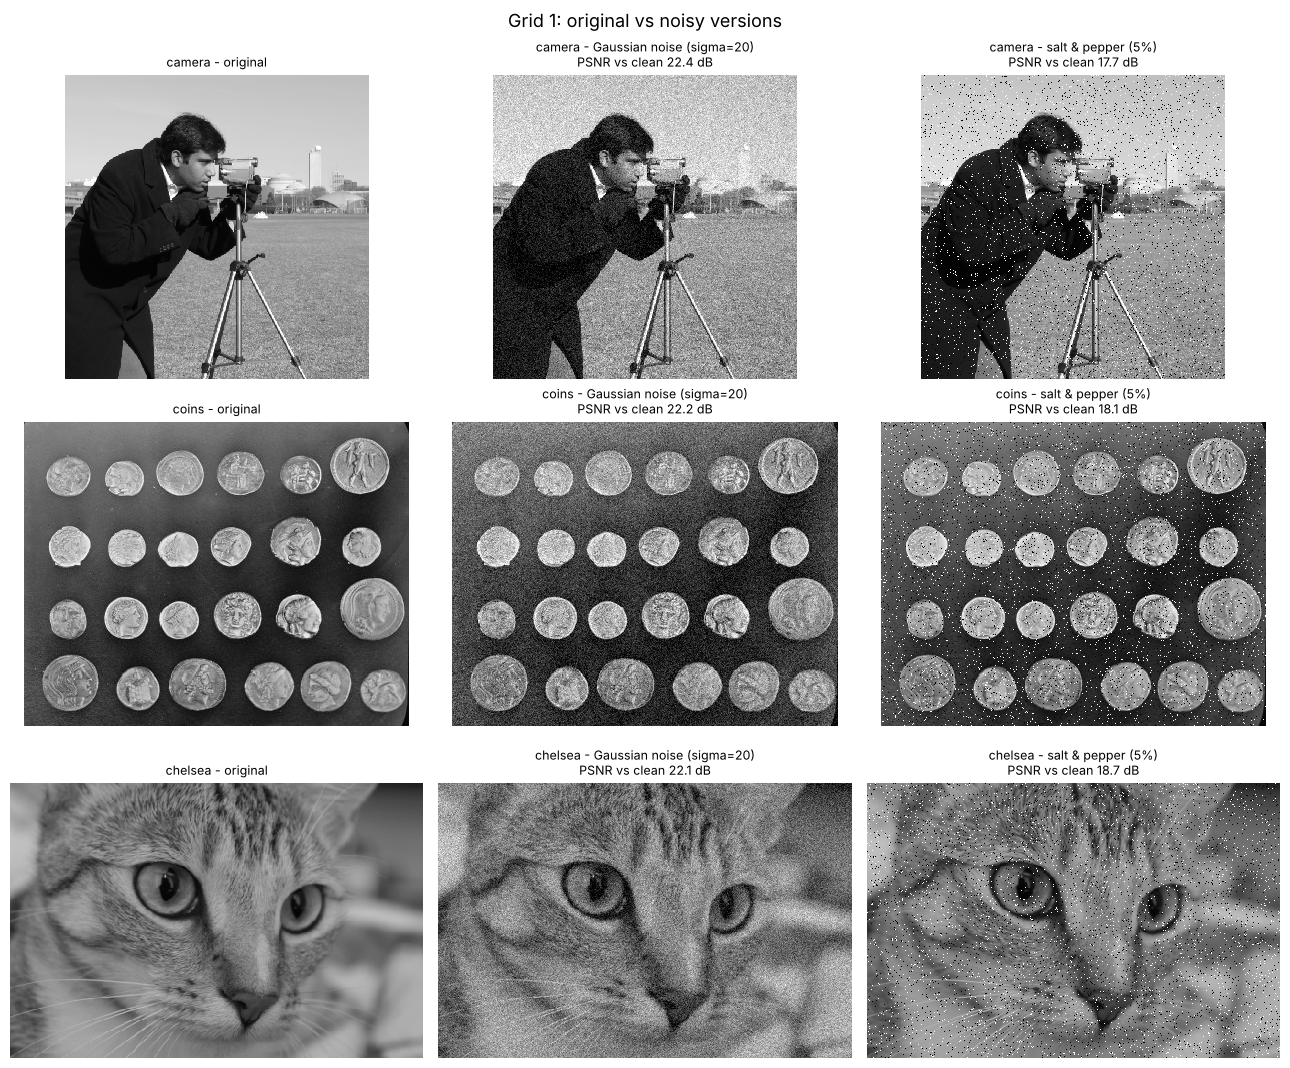

In [8]:
def show(ax, img, title):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title, fontsize=9)
    ax.axis("off")

fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for r, name in enumerate(originals):
    clean = originals[name]
    show(axes[r, 0], clean, f"{name} - original")
    g, s = noisy[(name, "gaussian")], noisy[(name, "salt&pepper")]
    show(axes[r, 1], g, f"{name} - Gaussian noise (sigma=20)\nPSNR vs clean {psnr(clean, g):.1f} dB")
    show(axes[r, 2], s, f"{name} - salt & pepper (5%)\nPSNR vs clean {psnr(clean, s):.1f} dB")
plt.suptitle("Grid 1: original vs noisy versions", fontsize=13)
plt.tight_layout()
plt.show()

### Grid 2 – mean vs Gaussian vs median (3×3) on every noisy image
Split into two figures (Gaussian noise, then salt-and-pepper) so each panel stays large enough to inspect. Each row is one test image; columns are: noisy input, mean 3×3, Gaussian 3×3, median 3×3.

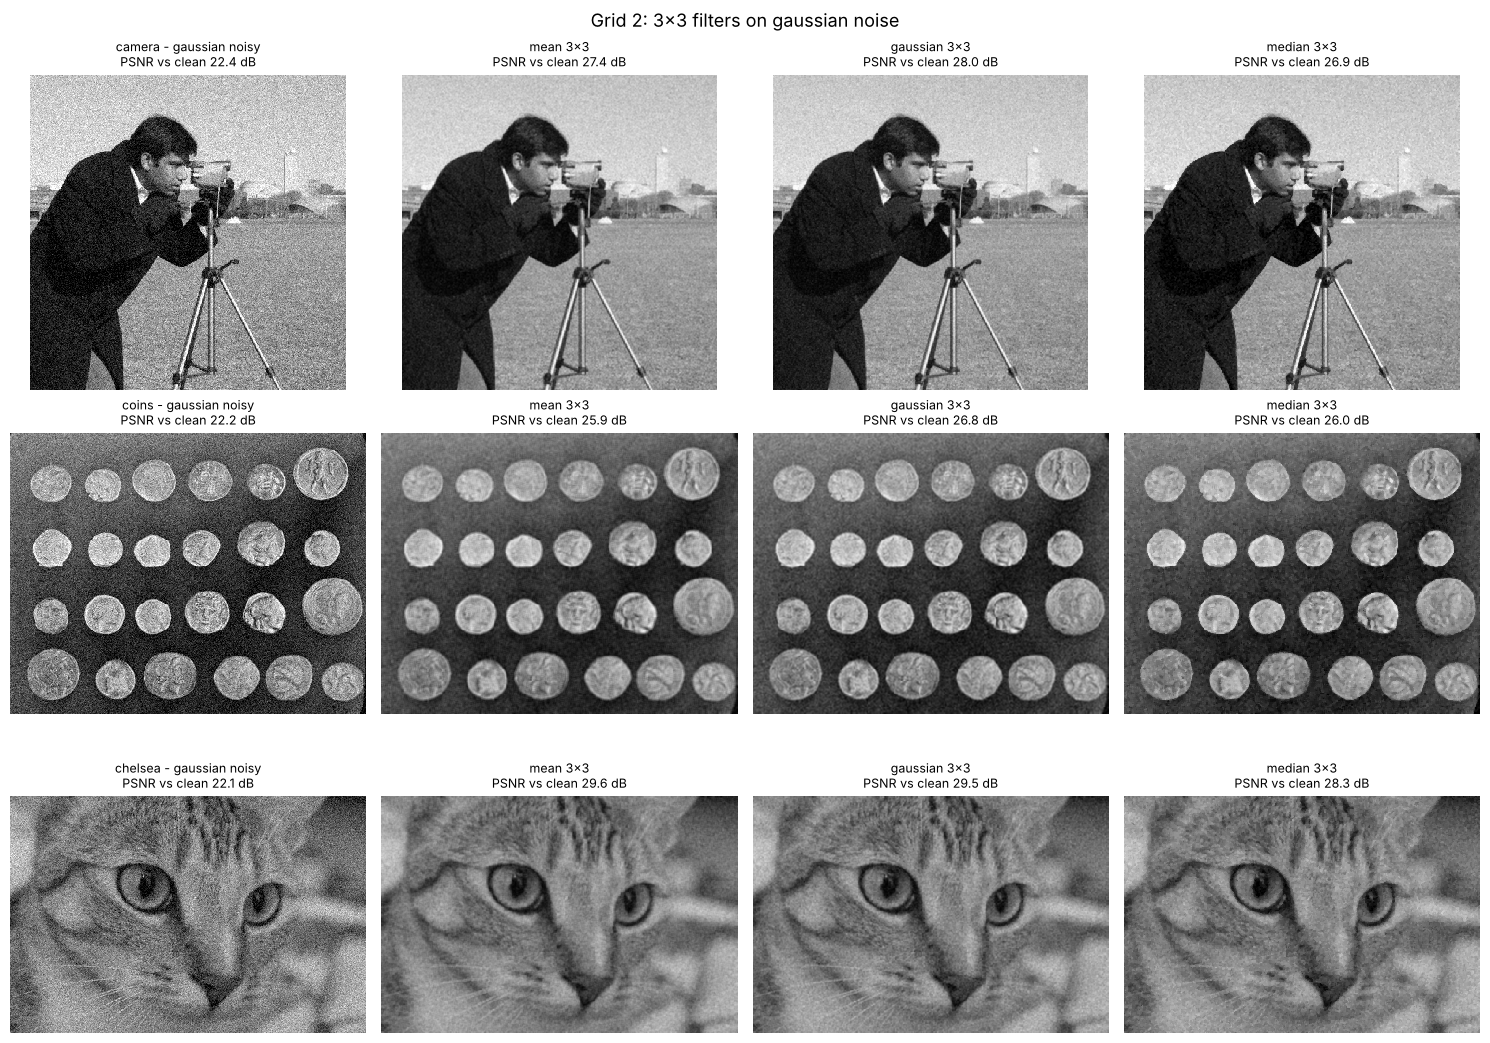

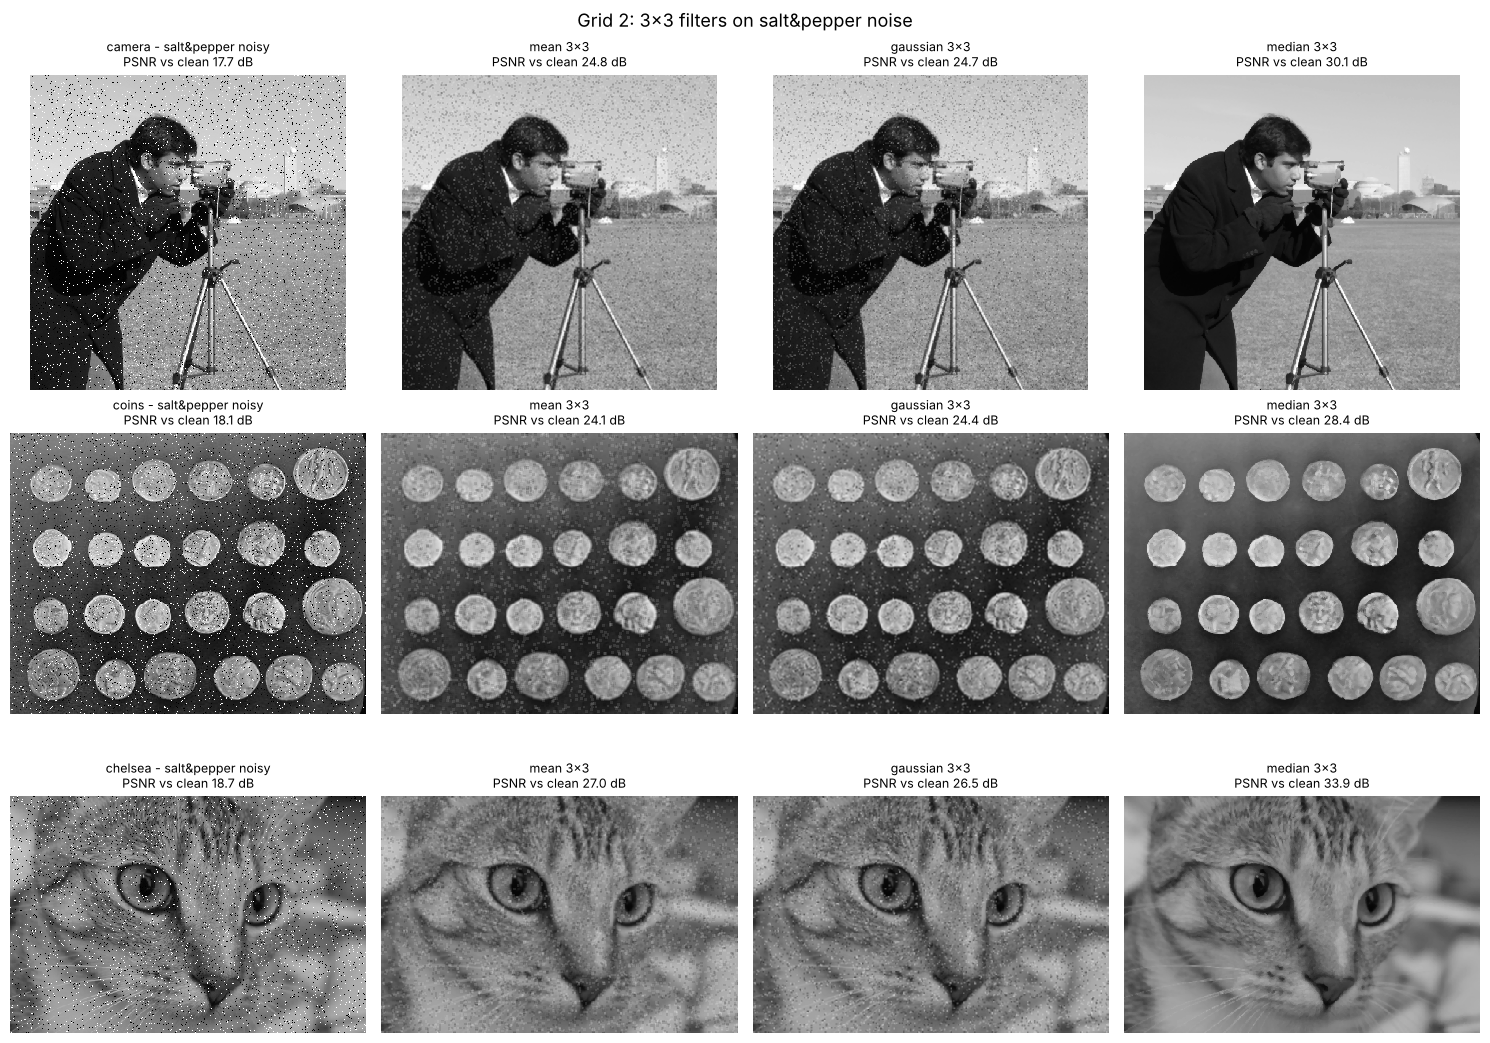

In [9]:
for kind in ("gaussian", "salt&pepper"):
    fig, axes = plt.subplots(3, 4, figsize=(15, 11))
    for r, name in enumerate(originals):
        clean, n = originals[name], noisy[(name, kind)]
        show(axes[r, 0], n, f"{name} - {kind} noisy\nPSNR vs clean {psnr(clean, n):.1f} dB")
        for c, fname in enumerate(FILTERS, start=1):
            out = results[(name, kind, fname, 3)]
            show(axes[r, c], out, f"{fname} 3x3\nPSNR vs clean {psnr(clean, out):.1f} dB")
    plt.suptitle(f"Grid 2: 3x3 filters on {kind} noise", fontsize=13)
    plt.tight_layout()
    plt.show()

In [10]:
# numeric summary for the report - PSNR (dB) against the CLEAN original (R6)
print(f"{'image':8s} {'noise':12s} {'noisy':>7s} | {'mean3':>7s} {'gauss3':>7s} {'median3':>8s} | {'mean5':>7s} {'gauss5':>7s} {'median5':>8s} | {'mean7':>7s} {'gauss7':>7s} {'median7':>8s}")
for (name, kind), n in noisy.items():
    clean = originals[name]
    row = [psnr(clean, n)]
    for k in (3, 5, 7):
        row += [psnr(clean, results[(name, kind, f, k)]) for f in FILTERS]
    print(f"{name:8s} {kind:12s} {row[0]:7.2f} | " + " | ".join(
        " ".join(f"{v:7.2f}" if i < 2 else f"{v:8.2f}" for i, v in enumerate(row[1 + 3*j: 4 + 3*j])) for j in range(3)))

image    noise          noisy |   mean3  gauss3  median3 |   mean5  gauss5  median5 |   mean7  gauss7  median7
camera   gaussian       22.40 |   27.37   27.99    26.95 |   26.17   27.81    26.84 |   24.85   26.95    25.80
camera   salt&pepper    17.69 |   24.83   24.71    30.12 |   25.09   25.65    27.84 |   24.25   25.67    26.23
coins    gaussian       22.20 |   25.86   26.79    26.00 |   24.03   26.02    25.36 |   22.78   24.87    24.50
coins    salt&pepper    18.11 |   24.10   24.37    28.37 |   23.37   24.59    26.30 |   22.38   24.04    25.19
chelsea  gaussian       22.12 |   29.55   29.46    28.28 |   29.56   30.37    29.09 |   28.75   30.29    28.73
chelsea  salt&pepper    18.73 |   27.00   26.50    33.94 |   28.31   28.11    30.98 |   28.05   28.82    29.70


### Grid 3 – filter × kernel size on the noisiest image
The "noisiest" image is the one whose noisy version has the lowest PSNR against its clean original.

noisiest image: camera with salt&pepper noise  (PSNR vs clean = 17.69 dB)


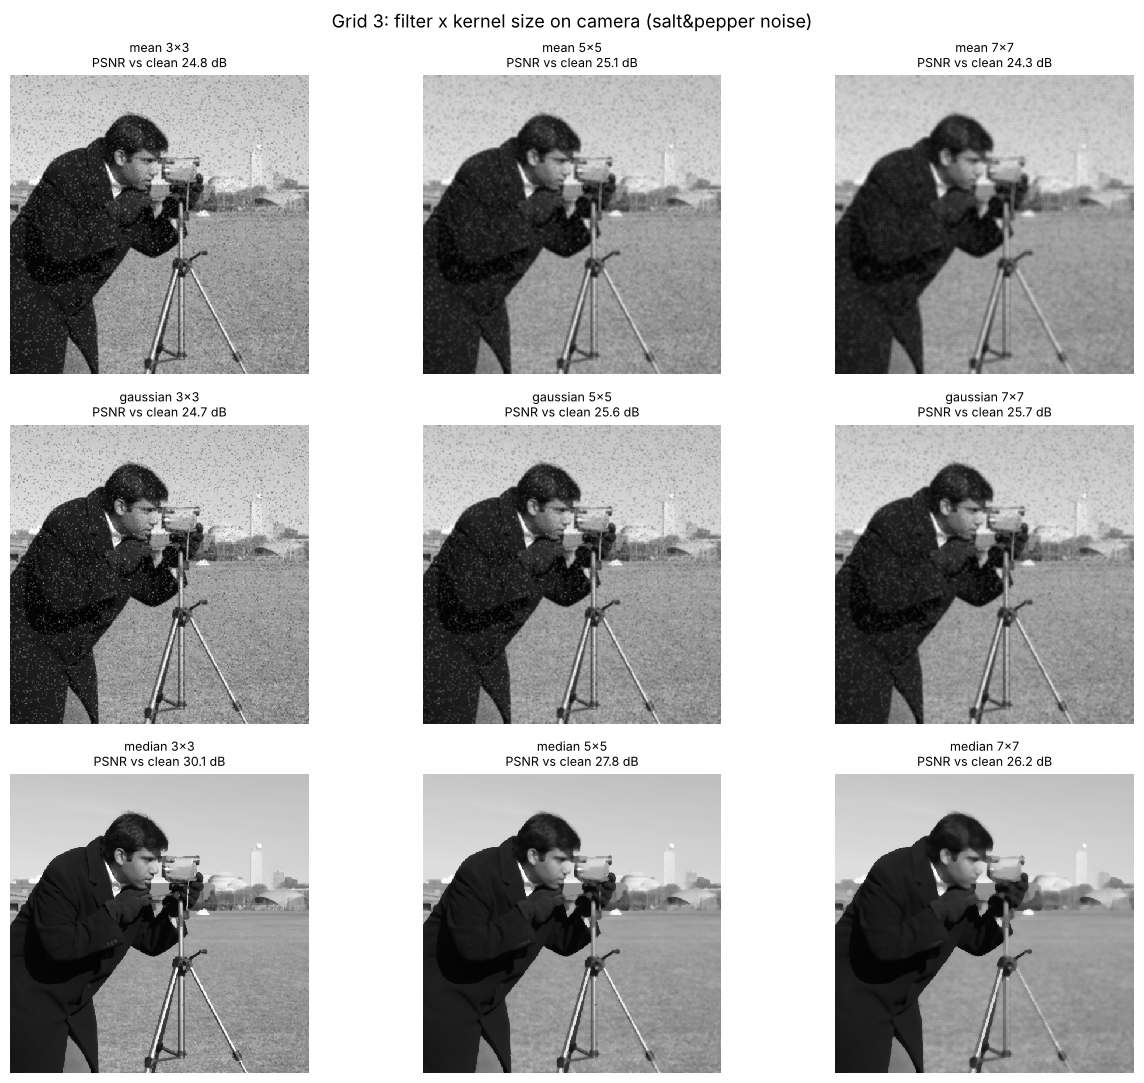

In [11]:
worst = min(noisy, key=lambda key: psnr(originals[key[0]], noisy[key]))
wname, wkind = worst
clean = originals[wname]
print(f"noisiest image: {wname} with {wkind} noise  (PSNR vs clean = {psnr(clean, noisy[worst]):.2f} dB)")

fig, axes = plt.subplots(3, 3, figsize=(13, 11))
for r, fname in enumerate(FILTERS):
    for c, k in enumerate((3, 5, 7)):
        out = results[(wname, wkind, fname, k)]
        show(axes[r, c], out, f"{fname} {k}x{k}\nPSNR vs clean {psnr(clean, out):.1f} dB")
plt.suptitle(f"Grid 3: filter x kernel size on {wname} ({wkind} noise)", fontsize=13)
plt.tight_layout()
plt.show()

---
## Extra evidence figures (used by the observation answers below)
**Edge test** – the position with the strongest horizontal edge in the lower half of the `camera` image is located automatically; a 1-D intensity profile through it shows how the mean and the Gaussian filter (both 5×5, applied to the *clean* image so only the kernel matters) treat a sharp step.

sharpest clean step edge: row 176, column 54  (plateau levels differ by 238 grey levels)
clean         10-90% transition width =  2.6 px | steepest single-pixel step = 112.0 grey levels | ringing (value outside the two plateaus): False
mean 5x5      10-90% transition width =  4.8 px | steepest single-pixel step =  45.0 grey levels | ringing (value outside the two plateaus): False
gaussian 5x5  10-90% transition width =  4.0 px | steepest single-pixel step =  65.0 grey levels | ringing (value outside the two plateaus): False
mean 7x7      10-90% transition width =  6.4 px | steepest single-pixel step =  34.0 grey levels | ringing (value outside the two plateaus): False
gaussian 7x7  10-90% transition width =  4.7 px | steepest single-pixel step =  51.0 grey levels | ringing (value outside the two plateaus): False


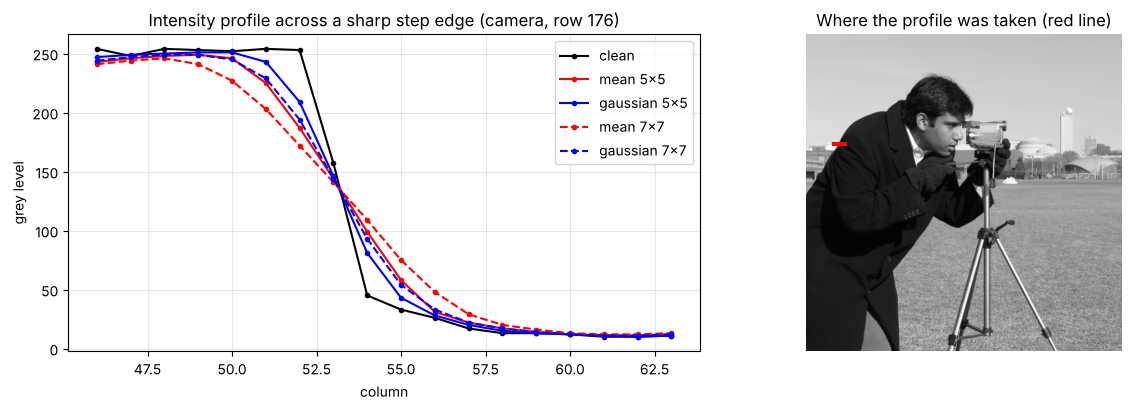

In [12]:
# find a clean step edge: flat bright/dark plateaus on both sides, biggest jump
cam = camera.astype(np.float64)
best = (0, 0, 0)
for y in range(0, 512, 2):
    for x in range(8, 504):
        L, R = cam[y, x - 8:x - 1], cam[y, x + 2:x + 9]
        if L.std() < 6 and R.std() < 6 and abs(L.mean() - R.mean()) > best[0]:
            best = (abs(L.mean() - R.mean()), y, x)
step, ey, ex = best
print(f"sharpest clean step edge: row {ey}, column {ex}  (plateau levels differ by {step:.0f} grey levels)")

xs = np.arange(ex - 8, ex + 10)
profiles = {
    "clean":        camera[ey, xs].astype(float),
    "mean 5x5":     mean_filter(camera, 5)[ey, xs].astype(float),
    "gaussian 5x5": gaussian_filter(camera, 5)[ey, xs].astype(float),
    "mean 7x7":     mean_filter(camera, 7)[ey, xs].astype(float),
    "gaussian 7x7": gaussian_filter(camera, 7)[ey, xs].astype(float),
}

def width_10_90(p):                    # pixels the transition needs between 10 % and 90 % of the step
    hi, lo = p[:3].mean(), p[-3:].mean()   # bright plateau on the left, dark plateau on the right
    def crossing(level):                   # first (sub-pixel) position where the profile drops below level
        i = np.where(p < level)[0][0]
        return (i - 1) + (p[i - 1] - level) / (p[i - 1] - p[i])
    return crossing(lo + 0.1 * (hi - lo)) - crossing(lo + 0.9 * (hi - lo))

for label, p in profiles.items():
    print(f"{label:13s} 10-90% transition width = {width_10_90(p):4.1f} px | steepest single-pixel step = "
          f"{np.abs(np.diff(p)).max():5.1f} grey levels | ringing (value outside the two plateaus): "
          f"{bool(p.max() > profiles['clean'].max() + 1 or p.min() < profiles['clean'].min() - 1)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
styles = {"clean": "k.-", "mean 5x5": "r.-", "gaussian 5x5": "b.-", "mean 7x7": "r.--", "gaussian 7x7": "b.--"}
for label, p in profiles.items():
    axes[0].plot(xs, p, styles[label], label=label)
axes[0].set_title(f"Intensity profile across a sharp step edge (camera, row {ey})")
axes[0].set_xlabel("column"); axes[0].set_ylabel("grey level"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].imshow(camera, cmap="gray", vmin=0, vmax=255)
axes[1].plot([xs[0], xs[-1]], [ey, ey], "r-", lw=3)
axes[1].set_title("Where the profile was taken (red line)"); axes[1].axis("off")
plt.tight_layout(); plt.show()

**Fine-detail test** – the tripod head and legs of `camera` (rows 310–430, columns 240–340) are thin structures a few pixels wide. The crop below compares the clean crop with each filter at 3×3 and at 7×7, all applied to the Gaussian-noise version, to see what 7×7 does to fine structure. The number under each crop is the mean Sobel gradient strength (how much edge/detail contrast is left; the clean crop is the reference).

mean {3: 103, 5: 68, 7: 46}
gaussian {3: 114, 5: 92, 7: 71}
median {3: 114, 5: 80, 7: 55}
clean crop Sobel strength: 131


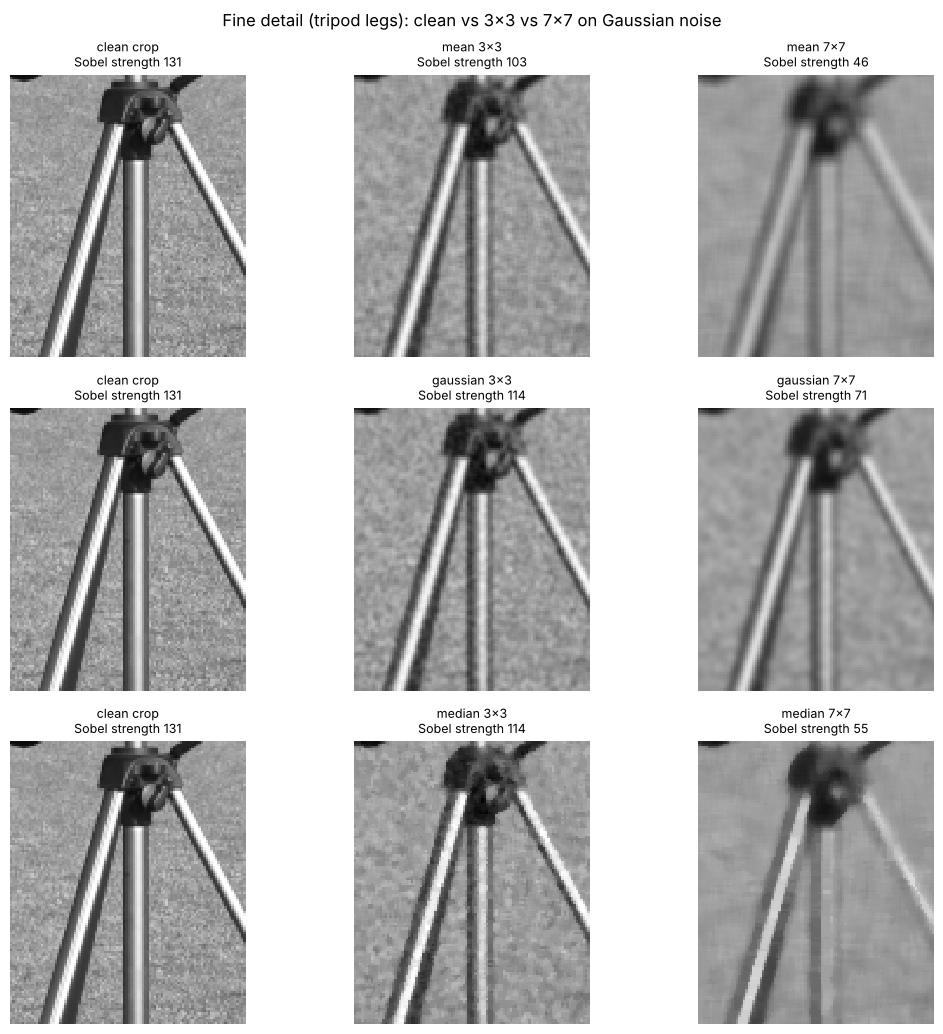

In [13]:
y0, y1, x0, x1 = 310, 430, 240, 340                     # tripod head + legs + grass
def sobel_mean(a):
    a = a.astype(np.float64)
    return np.hypot(cv2.Sobel(a, cv2.CV_64F, 1, 0), cv2.Sobel(a, cv2.CV_64F, 0, 1)).mean()

gnoisy = noisy[("camera", "gaussian")]
fig, axes = plt.subplots(3, 3, figsize=(11, 10.5))
for r, fname in enumerate(FILTERS):
    show(axes[r, 0], camera[y0:y1, x0:x1], f"clean crop\nSobel strength {sobel_mean(camera[y0:y1, x0:x1]):.0f}")
    for c, k in enumerate((3, 7), start=1):
        out = results[("camera", "gaussian", fname, k)][y0:y1, x0:x1]
        show(axes[r, c], out, f"{fname} {k}x{k}\nSobel strength {sobel_mean(out):.0f}")
for fname in FILTERS:
    print(fname, {k: round(sobel_mean(results[("camera", "gaussian", fname, k)][y0:y1, x0:x1])) for k in (3, 5, 7)})
print("clean crop Sobel strength:", round(sobel_mean(camera[y0:y1, x0:x1])))
plt.suptitle("Fine detail (tripod legs): clean vs 3x3 vs 7x7 on Gaussian noise", fontsize=12)
plt.tight_layout(); plt.show()

---
## Dry-Run Exercise 1 – Spike response
Neighbourhood (centre = 255, the eight neighbours = 40):

```
[[ 40,  40,  40],
 [ 40, 255,  40],
 [ 40,  40,  40]]
```

**(a) 3×3 mean kernel** (every weight 1/9)
sum = 8 × 40 + 255 = 320 + 255 = **575**
output = 575 / 9 = 63.89 → **64**

**(b) 3×3 Gaussian kernel (1-2-1 ÷ 16)** with weights `[[1,2,1],[2,4,2],[1,2,1]]`
* corners: 4 pixels × (1 × 40) = 160
* edge neighbours: 4 pixels × (2 × 40) = 320
* centre: 4 × 255 = 1020
* total = 160 + 320 + 1020 = **1500**
* output = 1500 / 16 = 93.75 → **94**

**(c) 3×3 median**
sorted values: 40, 40, 40, 40, 40, 40, 40, 40, 255 → the 5th (middle) value = **40**

So the mean pulls the spike down only to 64 and the Gaussian to 94 (the spike still leaks into the output, more so for the Gaussian because the centre weight is larger), while the median ignores it completely (40).

In [14]:
win = np.array([[40, 40, 40], [40, 255, 40], [40, 40, 40]], dtype=np.float64)
k_mean  = np.full((3, 3), 1 / 9)
k_gauss = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16

print("mean    : sum =", win.sum(), "-> 575/9 =", round(win.sum() / 9, 2),
      "| conv2d_loop centre =", round(conv2d_loop(win, k_mean)[1, 1], 2),
      "| rounded =", int(np.rint(conv2d_loop(win, k_mean)[1, 1])))
w16 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
print("gaussian: corners =", (win[::2, ::2] * 1).sum(), " edges =", (win[[0, 1, 1, 2], [1, 0, 2, 1]] * 2).sum(),
      " centre =", win[1, 1] * 4, " total =", (win * w16).sum(), "-> 1500/16 =", (win * w16).sum() / 16,
      "| conv2d_loop centre =", conv2d_loop(win, k_gauss)[1, 1], "| rounded =", int(np.rint(conv2d_loop(win, k_gauss)[1, 1])))
print("median  : sorted =", np.sort(win.ravel()).astype(int).tolist(),
      "-> middle =", int(np.median(win)),
      "| cv2.medianBlur centre =", cv2.medianBlur(win.astype(np.uint8), 3)[1, 1])

mean    : sum = 575.0 -> 575/9 = 63.89 | conv2d_loop centre = 63.89 | rounded = 64
gaussian: corners = 160.0  edges = 320.0  centre = 1020.0  total = 1500.0 -> 1500/16 = 93.75 | conv2d_loop centre = 93.75 | rounded = 94
median  : sorted = [40, 40, 40, 40, 40, 40, 40, 40, 255] -> middle = 40 | cv2.medianBlur centre = 40


---
## Dry-Run Exercise 2 – Reflect padding at a corner
Image:

```
[[10, 20, 30],
 [40, 50, 60],
 [70, 80, 90]]
```

With `mode="reflect"` the border is mirrored **without repeating the edge pixel**, so the value at index −1 is the value at index 1.
The 3×3 neighbourhood of pixel (0, 0) uses rows (1, 0, 1) and columns (1, 0, 1):

```
[[50, 40, 50],
 [20, 10, 20],
 [50, 40, 50]]
```

sum = (50 + 40 + 50) + (20 + 10 + 20) + (50 + 40 + 50) = 140 + 50 + 140 = **330**
mean = 330 / 9 = 36.67 → **37**

In [15]:
img3 = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]])
padded = np.pad(img3, 1, mode="reflect")
print("padded image:\n", padded)
nb = padded[0:3, 0:3]                         # neighbourhood centred on (0, 0)
print("\nneighbourhood of (0,0):\n", nb)
print("sum =", nb.sum(), "| mean =", round(nb.sum() / 9, 2), "| rounded =", int(np.rint(nb.sum() / 9)))
print("conv2d_loop (0,0)  =", round(conv2d_loop(img3, mean_kernel(3))[0, 0], 2))
print("cv2.blur   (0,0)  =", cv2.blur(img3.astype(np.uint8), (3, 3))[0, 0])

padded image:
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

neighbourhood of (0,0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]]
sum = 330 | mean = 36.67 | rounded = 37
conv2d_loop (0,0)  = 36.67
cv2.blur   (0,0)  = 37


---
## Observations – answers drawn from my own figures (all judged against the clean originals, R6)

**1. Gaussian noise – best and worst filter.**
*Best: the Gaussian filter.* In the PSNR table it beats both other filters at 3×3 on `camera` (27.99 dB vs 27.37 mean / 26.95 median) and on `coins` (26.79 vs 25.86 / 26.00), and it ties the mean on `chelsea` (29.46 vs 29.55). At 5×5 it wins on all three images (27.81, 26.02, 30.37 dB). Visually, in Grid 2 the grass area at the bottom of `camera` and the dark background between the `coins` are the smoothest in the Gaussian column, while edges such as the coat outline stay crisp.
*Worst: the median (at 3×3).* It is lowest on `camera` (26.95 dB) and `chelsea` (28.28 dB), and in Grid 2 its dark `coins` background is left with blotchy patches rather than a smooth field – the median only picks one of the nine noisy values, it does not average the noise away. (On `coins` the mean is 0.14 dB lower than the median, which is a tie; and at 7×7 the mean becomes the lowest on `camera` and `coins`, because it blurs most – so "worst" depends slightly on the size, but the median is the weakest at the default 3×3.)

**2. Salt-and-pepper noise – best filter and why the other two fail.**
*Best: the median.* At 3×3 it reaches 30.12 dB on `camera`, 28.37 on `coins` and 33.94 on `chelsea`, while the best of mean/Gaussian only reaches 24.83, 24.37 and 27.00 – a gain of about 4–7 dB. In Grid 3 (noisiest image = `camera` with salt-and-pepper) the bottom row is almost completely clean: the dark coat and the sky have no white/black specks left.
*Why mean and Gaussian fail:* both are weighted averages, so an extreme pixel (0 or 255) is blended into the output instead of being removed. Dry-run 1 shows it: one 255 spike in a flat 40 area leaves the mean output at 64 and the Gaussian output at 94, instead of 40. In Grid 3 the mean and Gaussian rows still show grey smudges and bright/dark specks on the coat and the sky; at 7×7 the mean only turns the specks into faint blotches while blurring the whole picture (PSNR 24.3 dB, lower than at 3×3).

**3. Mean vs Gaussian on a sharp edge.**
I took the sharpest flat-sided step in `camera` (row 176, column 54: the bright sky on the left jumps to the dark coat on the right by 238 grey levels; see the profile figure). The clean edge takes 2.6 px to go from 10 % to 90 %. After a 5×5 **mean** it needs 4.8 px and the steepest one-pixel step falls from 112 to 45 grey levels; after a 5×5 **Gaussian** it needs 4.0 px and the steepest step is 65. At 7×7 the numbers are 6.4 px (mean) vs 4.7 px (Gaussian). So the Gaussian keeps the edge noticeably sharper: its weights are largest at the centre and fall off, while the mean gives far pixels the same weight as near ones and smears the step into a wide straight ramp (red line in the figure is wider/flatter than the blue one). Neither filter creates ringing, because all their weights are positive.

**4. What happens to fine detail at 7×7.**
In the tripod crop (`camera`, rows 310–430, columns 240–340) the clean image has Sobel strength 131. At 3×3 the legs, centre post and tripod head are still clearly separate (mean 103, Gaussian 114, median 114). At 7×7 the strength falls to 46 (mean), 71 (Gaussian) and 55 (median): the two thin legs and the centre post melt into soft grey bands, the bolt/dial on the tripod head fades to a smudge and the grass texture is wiped out. The kernel is now larger than the structures it is trying to keep. The PSNR table shows the same cost: for the median on `camera` with salt-and-pepper noise PSNR drops from 30.12 dB (3×3) to 27.84 (5×5) and 26.23 (7×7) – more smoothing than needed removes real detail as well as noise.

**5. Why the kernel size must be odd.**
A k×k window must have one pixel exactly in the centre with the same number of neighbours on each side, i.e. k = 2r + 1, and the output is written to that centre pixel. With an even size (e.g. 4×4) there is no centre: the result would sit half a pixel off, the padding could not be the same on both sides, and the median of an even count of values has no single middle value. OpenCV enforces this: in my compliance check `cv2.medianBlur(img, 4)` raised a `cv2.error`, and my own wrapper raised a `ValueError`. That is also why the padding in `conv2d_loop` is `k // 2` on every side.

---
## Viva Preparation (brief answers)

**1. What is a kernel?**
A small matrix of weights (e.g. 3×3) that is slid over the image. At each pixel the neighbourhood is multiplied element-wise by the (flipped) kernel and the products are summed to give the output pixel. The weights decide the effect: equal weights give a mean blur, bell-shaped weights give a Gaussian blur.

**2. Apply a 3×3 mean kernel to a 3×3 window given on the spot.**
Add all nine values and divide by 9 (each weight is 1/9). Example with the window `[[10,20,30],[40,50,60],[70,80,90]]`: sum = 450, 450 / 9 = **50**. For the spike window of Dry-Run 1: 575 / 9 = 63.89 → 64.

**3. Why does the median remove a 255 spike but the mean does not?**
The mean adds every value, so the spike contributes 255/9 ≈ 28 grey levels to the output (40 became 64 in Dry-Run 1). The median sorts the nine values; a single extreme value always lands at the very end of the sorted list, never in the middle (5th) position, so it is simply ignored (output stays 40). More than half of the window would have to be spikes before the median changes.

**4. Why do the Gaussian weights sum to 16, and why divide by it?**
The 1-D weights are 1-2-1 (sum 4). The 3×3 kernel is their outer product, so its sum is 4 × 4 = 16. Dividing by 16 makes the weights sum to 1 (R3), so a flat region keeps its brightness: a flat patch of 100 gives 1600 / 16 = 100. Without the division the image would become 16 times brighter.

**5. Why do we pad the border before filtering?**
Pixels on the border do not have a full neighbourhood. Padding (here by reflection, without repeating the edge pixel) supplies the missing neighbours so that the kernel can be applied everywhere and the output has the same size as the input (R1). Without padding the output would shrink by `k - 1` pixels in each direction. Reflection is used because it continues the local image content naturally instead of introducing black borders.

**6. Which filter for salt-and-pepper noise, and why?**
The median filter. The spikes are extreme outliers (0 or 255); the median ignores outliers and picks a value that really exists in the neighbourhood, so impulses disappear and edges stay fairly sharp. In my results it gave 30.12 / 28.37 / 33.94 dB at 3×3 against at most 24.83 / 24.37 / 27.00 dB for mean and Gaussian.

---
## Final check – the original images were never modified

In [16]:
for k, v in originals.items():
    print(f"{k:8s} unchanged:", hashlib.md5(v.tobytes()).hexdigest() == fingerprints[k], "| writeable:", v.flags.writeable)

camera   unchanged: True | writeable: False
coins    unchanged: True | writeable: False
chelsea  unchanged: True | writeable: False
